# Day 12: Linear Regression Across 12 Industries

This notebook follows the  style: a short explanation, runnable code, and saved results. It fits one linear regression model for each continuous prediction task described in the Day 12 help document. Each matching CSV is split 80/20 into training and test data. The notebook reports R-squared, MAE, and RMSE, then reviews fitted coefficients and residual behavior.

## 1. Load the datasets and define each prediction task

For each industry, X contains the listed predictors and y is the continuous outcome in that domain's CSV. Numeric category columns such as season, plan type, and role level are one-hot encoded; other numeric features are standardized inside the training pipeline.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TASKS={
'Supply Chain / Logistics':('supply_chain.csv',['price','promotion','season','region_factor'],'demand'),
'BFSI / Finance':('bfsi.csv',['income','credit_limit','txn_frequency'],'spend'),
'AdTech / E-commerce':('adtech.csv',['clicks','session_time','cart_adds'],'revenue'),
'Telecom':('telecom.csv',['data_usage','call_duration','plan_type'],'bill_amount'),
'Cybersecurity':('cybersecurity.csv',['traffic','packet_size','connections'],'latency'),
'IT / Infrastructure':('it_infra.csv',['requests','memory','users'],'cpu_usage'),
'Healthcare':('healthcare.csv',['age','bmi','glucose','blood_pressure'],'risk_score'),
'HR Analytics':('hr.csv',['experience','performance','role_level'],'salary'),
'Civil Engineering':('civil.csv',['cement','water','aggregates'],'strength'),
'Energy / Utilities':('energy.csv',['temperature','humidity','appliances'],'energy_usage'),
'EdTech':('edtech.csv',['study_hours','attendance','quiz_score'],'final_score'),
'Automotive / ADAS':('automotive.csv',['speed','acceleration','braking'],'mileage')}
possible_roots=[Path('../Regression_datasets-20261023T180311Z-1-001/Regression_datasets'),Path('Regression_datasets-20261023T180311Z-1-001/Regression_datasets'),Path('Assignment Day-12/Regression_datasets-20261023T180311Z-1-001/Regression_datasets')]
DATA_ROOT=next((p for p in possible_roots if p.exists()),None)
if DATA_ROOT is None: raise FileNotFoundError('Could not locate the Regression_datasets folder.')
print('Dataset folder:',DATA_ROOT.resolve())
print('Tasks:',len(TASKS))

Dataset folder: C:\Users\hp\Assignments-Day-3\Assignment Day-12\Regression_datasets-20261023T180311Z-1-001\Regression_datasets
Tasks: 12


## 2. Check data and fit each model

The preprocessing pipeline learns scaling and category encoding from training rows only. Each task uses the same 80/20 random split seed so results can be reproduced. R-squared compares the model with a mean-value baseline; MAE and RMSE express typical error in the target's units.

In [2]:
categorical_names={'season','promotion','plan_type','role_level'}
rows=[]; fitted_models={}; task_data={}
for task,(filename,features,target) in TASKS.items():
    df=pd.read_csv(DATA_ROOT/filename)
    X=df[features].copy(); y=df[target].copy()
    missing=int(df[features+[target]].isna().sum().sum())
    if missing:
        raise ValueError(f'{task}: handle {missing} missing values before fitting.')
    categorical=[c for c in features if c in categorical_names]
    numeric=[c for c in features if c not in categorical]
    transformers=[]
    if numeric: transformers.append(('numeric',StandardScaler(),numeric))
    if categorical: transformers.append(('categorical',OneHotEncoder(handle_unknown='ignore',drop='first'),categorical))
    prep=ColumnTransformer(transformers)
    model=Pipeline([('preprocess',prep),('regression',LinearRegression())])
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    rows.append({'Industry':task,'Rows':len(df),'Features':', '.join(features),'Target':target,'R2':r2_score(y_test,pred),'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'Missing':missing})
    fitted_models[task]=model
    task_data[task]=(X_train,X_test,y_train,y_test,pred)
results=pd.DataFrame(rows).set_index('Industry').sort_values('R2',ascending=False)
print(results.round(3).to_string())

                           Rows                                 Features        Target     R2       MAE      RMSE  Missing
Industry                                                                                                                  
HR Analytics              10000      experience, performance, role_level        salary  0.983  2402.170  2980.016        0
Civil Engineering         10000                cement, water, aggregates      strength  0.973     7.957    10.030        0
Telecom                   10000     data_usage, call_duration, plan_type   bill_amount  0.973    15.839    19.972        0
EdTech                    10000      study_hours, attendance, quiz_score   final_score  0.953     4.022     5.053        0
AdTech / E-commerce       10000          clicks, session_time, cart_adds       revenue  0.945    23.897    30.185        0
IT / Infrastructure       10000                  requests, memory, users     cpu_usage  0.924     4.028     5.076        0
Energy / Utiliti

## 3. Compare fit across the 12 tasks

Target units differ by domain, so compare R-squared across tasks more directly. Use MAE and RMSE within each domain in its original units. A low or negative test R-squared means this linear model does not explain the held-out variation well.

Best held-out R2: HR Analytics 0.983
Lowest held-out R2: Supply Chain / Logistics 0.602


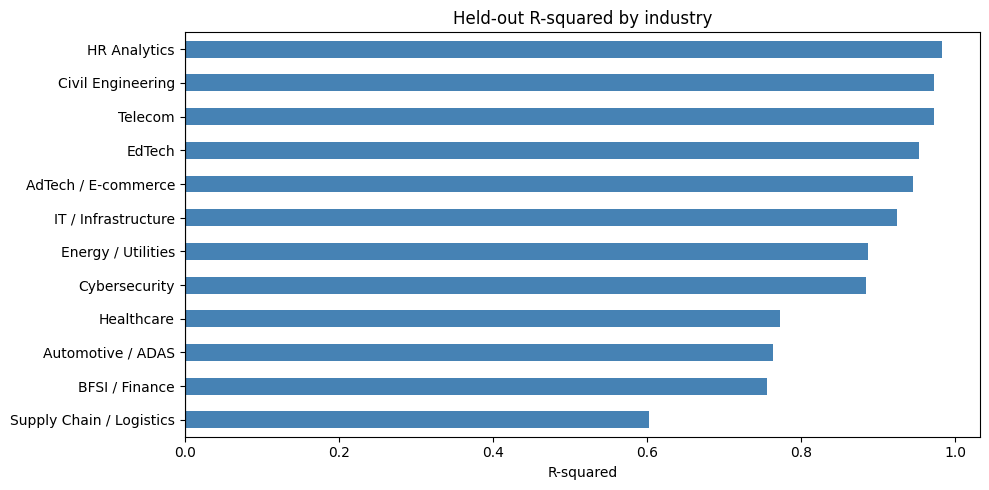

In [3]:
fig,ax=plt.subplots(figsize=(10,5))
results['R2'].sort_values().plot(kind='barh',ax=ax,color='steelblue')
ax.axvline(0,color='black',linewidth=0.8)
ax.set(title='Held-out R-squared by industry',xlabel='R-squared',ylabel='')
plt.tight_layout();plt.show()
print('Best held-out R2:',results.index[0],round(results.iloc[0]['R2'],3))
print('Lowest held-out R2:',results.index[-1],round(results.iloc[-1]['R2'],3))

## 4. Inspect fitted coefficients and residuals

The pipeline standardizes continuous predictors, so their coefficients represent the fitted target change for a one-standard-deviation feature change, holding other inputs fixed. One-hot category coefficients compare each category with its omitted baseline. These are associations in the fitted model, not causal effects.

In [4]:
coef_rows=[]
for task,model in fitted_models.items():
    names=model.named_steps['preprocess'].get_feature_names_out()
    values=model.named_steps['regression'].coef_
    for feature,value in sorted(zip(names,values),key=lambda item:abs(item[1]),reverse=True):
        coef_rows.append({'Industry':task,'Feature':feature,'Coefficient':value})
coef_table=pd.DataFrame(coef_rows)
for task in TASKS:
    print('\n'+task)
    print(coef_table[coef_table.Industry==task].head(4).round(3).to_string(index=False))


Supply Chain / Logistics
                Industry                  Feature  Coefficient
Supply Chain / Logistics           numeric__price      -53.391
Supply Chain / Logistics categorical__promotion_1       31.311
Supply Chain / Logistics   numeric__region_factor       23.667
Supply Chain / Logistics   categorical__season_11      -19.181

BFSI / Finance
      Industry                Feature  Coefficient
BFSI / Finance  numeric__credit_limit     7592.705
BFSI / Finance        numeric__income     4507.034
BFSI / Finance numeric__txn_frequency      933.648

AdTech / E-commerce
           Industry               Feature  Coefficient
AdTech / E-commerce    numeric__cart_adds      112.177
AdTech / E-commerce numeric__session_time       59.518
AdTech / E-commerce       numeric__clicks       14.174

Telecom
Industry                  Feature  Coefficient
 Telecom categorical__plan_type_3      199.790
 Telecom categorical__plan_type_2       99.833
 Telecom      numeric__data_usage       70.781
 

Civil residual mean: -0.321 | MAE: 7.957


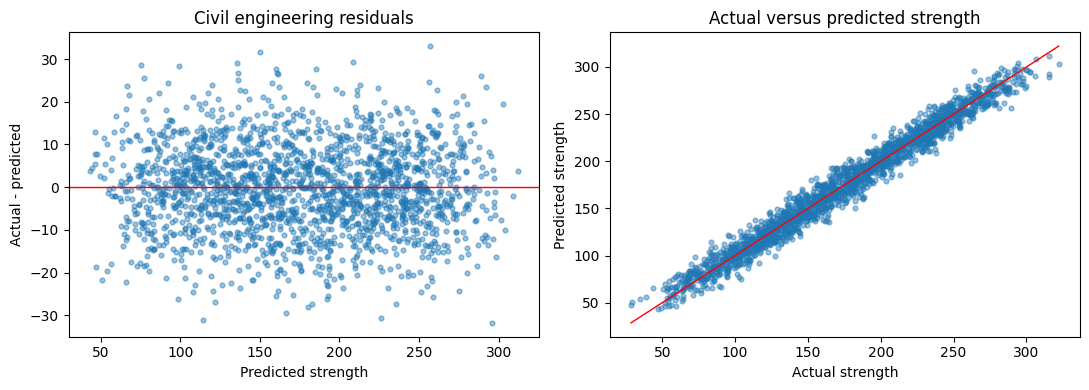

In [5]:
# Residual check for the civil strength example.
example='Civil Engineering'
X_train,X_test,y_train,y_test,pred=task_data[example]
residuals=y_test-pred
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(pred,residuals,s=12,alpha=0.45)
axes[0].axhline(0,color='red',linewidth=1)
axes[0].set(title='Civil engineering residuals',xlabel='Predicted strength',ylabel='Actual - predicted')
axes[1].scatter(y_test,pred,s=12,alpha=0.45)
low=min(y_test.min(),pred.min());high=max(y_test.max(),pred.max())
axes[1].plot([low,high],[low,high],color='red',linewidth=1)
axes[1].set(title='Actual versus predicted strength',xlabel='Actual strength',ylabel='Predicted strength')
plt.tight_layout();plt.show()
print('Civil residual mean:',round(float(residuals.mean()),3),'| MAE:',round(mean_absolute_error(y_test,pred),3))

## 5. Recommendation and limitations

Linear regression is a useful interpretable baseline for each continuous target. Use the held-out metrics and residual plot to decide where it is adequate. If residuals show curvature, uneven spread, or important patterns, add domain features, transform the target, or compare nonlinear models. Do not compare MAE/RMSE across different target units as if they were directly equivalent.